# Task 2 (Part 1): ML & DL Baselines on Ninapro DB3


## 0. Setup & Environment

In [ ]:
!pip install -q xgboost lightgbm

import os, re, time, shutil, subprocess, urllib.request, warnings
import numpy as np
import pandas as pd
import scipy.io as sio
import matplotlib.pyplot as plt
import seaborn as sns

from numpy.lib.stride_tricks import sliding_window_view
from sklearn.preprocessing import RobustScaler, label_binarize
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    roc_curve, precision_recall_curve, auc
)
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
import xgboost as xgb
import lightgbm as lgb

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Using device:', DEVICE)

ZIP_DIR = '/content/Ninapro_Zips'
LOCAL_DIR = '/content/Ninapro_DB3'
os.makedirs(ZIP_DIR, exist_ok=True)
os.makedirs(LOCAL_DIR, exist_ok=True)

Using device: cpu


## 1. Download & Extract Ninapro DB3 Dataset (All 11 Amputee Subjects)

In [ ]:
BASE_URL = 'https://ninapro.hevs.ch/files/db3_Preproc'
failed_zips = []

for s in range(1, 12):
    zf = f's{s}_0.zip'
    zip_path = os.path.join(ZIP_DIR, zf)
    if not os.path.exists(zip_path) or os.path.getsize(zip_path) < 1000:
        url = f'{BASE_URL}/{zf}'
        print(f'Downloading {zf} ...')
        r_dl = subprocess.run(['wget', '-q', '-c', url, '-O', zip_path])
        if r_dl.returncode != 0:
            urllib.request.urlretrieve(url, zip_path)

    r = subprocess.run(['unzip', '-o', '-q', zip_path, '-d', LOCAL_DIR],
                       capture_output=True, text=True)
    if r.returncode != 0:
        if os.path.exists(zip_path): os.remove(zip_path)
        subprocess.run(['wget', '-q', f'{BASE_URL}/{zf}', '-O', zip_path])
        r = subprocess.run(['unzip', '-o', '-q', zip_path, '-d', LOCAL_DIR],
                           capture_output=True, text=True)
        if r.returncode != 0:
            failed_zips.append(zf)

for root, dirs, files in os.walk(LOCAL_DIR):
    for f in files:
        src = os.path.join(root, f)
        if f.startswith('._'):
            os.remove(src)
        elif f.endswith('.mat') and root != LOCAL_DIR:
            shutil.move(src, os.path.join(LOCAL_DIR, f))
shutil.rmtree(os.path.join(LOCAL_DIR, '__MACOSX'), ignore_errors=True)

mat_files = sorted(os.path.join(LOCAL_DIR, f) for f in os.listdir(LOCAL_DIR)
                   if f.endswith('.mat') and not f.startswith('._'))
print(f'Extracted {len(mat_files)}/33 .mat files. Errors: {failed_zips or "none"}')

Extracted 33/33 .mat files. Errors: none


## 2. Window Feature Extraction

In [ ]:
WIN, STEP = 300, 150
FEATURE_TYPES = ['MAV', 'RMS', 'VAR', 'WL', 'ZC', 'SSC']
THR_FACTOR = 0.1
EX_OFFSET = {1: 0, 2: 0, 3: 0}

def window_features(emg, lbl):
    emg = emg.astype(np.float64) * 1000.0
    thr = THR_FACTOR * emg.std(axis=0)[None, :, None]
    W = sliding_window_view(emg, WIN, axis=0)[::STEP]
    L = sliding_window_view(lbl, WIN)[::STEP]
    ok = (L == L[:, :1]).all(axis=1)
    W, y = W[ok], L[ok, 0]
    d = np.diff(W, axis=-1)
    mav = np.abs(W).mean(-1)
    rms = np.sqrt((W ** 2).mean(-1))
    var = W.var(-1)
    wl  = np.abs(d).sum(-1)
    zc  = ((W[..., :-1] * W[..., 1:] < 0) & (np.abs(d) >= thr)).sum(-1)
    ssc = ((d[..., :-1] * d[..., 1:] < 0) &
           (np.abs(d[..., :-1] - d[..., 1:]) >= thr)).sum(-1)
    return np.hstack([mav, rms, var, wl, zc, ssc]), y

X_parts, y_parts, s_parts = [], [], []
n_channels = 12

for fp in mat_files:
    base = os.path.basename(fp)
    m = re.match(r'S(\d+)_E(\d+)', base)
    sid, ex = int(m.group(1)), int(m.group(2))
    try:
        mat = sio.loadmat(fp)
        emg, lbl = mat['emg'], mat['restimulus'].ravel().astype(np.int64)
        lbl = np.where(lbl > 0, lbl + EX_OFFSET.get(ex, 0), 0)
        Xf, yf = window_features(emg, lbl)
        X_parts.append(Xf); y_parts.append(yf)
        s_parts.append(np.full(len(yf), sid))
    except Exception as e:
        print(f'Skipped {base}: {e}')

feat_cols = [f'{f}_Ch{c}' for f in FEATURE_TYPES for c in range(1, n_channels + 1)]
df = pd.DataFrame(np.vstack(X_parts), columns=feat_cols)
df['Gesture_Label'] = np.concatenate(y_parts)
df['Subject_ID']    = np.concatenate(s_parts)

unique_classes = sorted(df['Gesture_Label'].unique())
label_map = {c: i for i, c in enumerate(unique_classes)}
df['y'] = df['Gesture_Label'].map(label_map)
NUM_CLASSES = len(unique_classes)
print(f'Dataset shape: {df.shape} | Classes: {NUM_CLASSES} | Subjects: {sorted(df.Subject_ID.unique())}')

Dataset shape: (353568, 75) | Classes: 50 | Subjects: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11)]


## 3. Leakage-Free Subject-Wise Split & Preprocessing

In [13]:
TRAIN_SUBJ = [1, 2, 3, 4, 5, 6, 7, 8]
VAL_SUBJ   = [9]
TEST_SUBJ  = [10, 11]

df_train_raw = df[df['Subject_ID'].isin(TRAIN_SUBJ)].copy()
df_val       = df[df['Subject_ID'].isin(VAL_SUBJ)].copy()
df_test      = df[df['Subject_ID'].isin(TEST_SUBJ)].copy()

active_med = int(df_train_raw[df_train_raw['y'] > 0]['y'].value_counts().median())
df_rest_train = df_train_raw[df_train_raw['y'] == 0].sample(n=min(len(df_train_raw[df_train_raw['y']==0]), active_med * 2), random_state=42)
df_act_train  = df_train_raw[df_train_raw['y'] > 0]
df_train = pd.concat([df_rest_train, df_act_train], ignore_index=True).sample(frac=1.0, random_state=42).reset_index(drop=True)

print(f'Split sizes (windows) -> Train (Subj {TRAIN_SUBJ}): {len(df_train):,} (raw: {len(df_train_raw):,}) | '
      f'Val (Subj {VAL_SUBJ}): {len(df_val):,} | Test (Subj {TEST_SUBJ}): {len(df_test):,}')

skew_cols = [c for c in feat_cols if c.startswith(('MAV', 'RMS', 'VAR', 'WL'))]

def transform_skew(frame):
    X = frame[feat_cols].copy()
    for c in skew_cols:
        X[c] = np.log1p(np.maximum(0.0, X[c]))
    return X.values

scaler = RobustScaler()
X_train = scaler.fit_transform(transform_skew(df_train))
X_val   = scaler.transform(transform_skew(df_val))
X_test  = scaler.transform(transform_skew(df_test))

y_train = df_train['y'].values
y_val   = df_val['y'].values
y_test  = df_test['y'].values

Split sizes (windows) -> Train (Subj [1, 2, 3, 4, 5, 6, 7, 8]): 168,816 (raw: 258,861) | Val (Subj [9]): 32,962 | Test (Subj [10, 11]): 61,745


## 4. Unified Evaluation Helper

In [17]:
y_test_bin = label_binarize(y_test, classes=list(range(NUM_CLASSES)))
results_list = []
model_predictions = {}
model_probabilities = {}

def evaluate_model(name, y_true, y_pred, y_prob, train_time):
    acc      = accuracy_score(y_true, y_pred)
    prec_m   = precision_score(y_true, y_pred, average='macro', zero_division=0)
    rec_m    = recall_score(y_true, y_pred, average='macro', zero_division=0)
    f1_m     = f1_score(y_true, y_pred, average='macro', zero_division=0)
    prec_w   = precision_score(y_true, y_pred, average='weighted', zero_division=0)
    rec_w    = recall_score(y_true, y_pred, average='weighted', zero_division=0)
    f1_w     = f1_score(y_true, y_pred, average='weighted', zero_division=0)

    try:
        roc_auc = roc_auc_score(y_test_bin, y_prob, average='macro', multi_class='ovr')
    except Exception:
        roc_auc = np.nan
    try:
        pr_auc  = average_precision_score(y_test_bin, y_prob, average='macro')
    except Exception:
        pr_auc  = np.nan

    res = {
        'Model': name,
        'Macro-F1': round(f1_m, 4),
        'Weighted-F1': round(f1_w, 4),
        'Accuracy': round(acc, 4),
        'Macro-Precision': round(prec_m, 4),
        'Macro-Recall': round(rec_m, 4),
        'Weighted-Precision': round(prec_w, 4),
        'Weighted-Recall': round(rec_w, 4),
        'ROC-AUC (OvR)': round(roc_auc, 4),
        'PR-AUC (OvR)': round(pr_auc, 4),
        'Train Time (s)': round(train_time, 2)
    }
    results_list.append(res)
    model_predictions[name] = y_pred
    model_probabilities[name] = y_prob
    print(f'[{name:18s}] Macro-F1: {f1_m:.4f} | Acc: {acc:.4f} | Macro-Recall: {rec_m:.4f} | ROC-AUC: {roc_auc:.4f} | Time: {train_time:.1f}s')
    return res

## 5. Train & Evaluate Classical ML Baselines

In [ ]:
svm_idx = np.random.RandomState(42).choice(len(X_train), size=min(35000, len(X_train)), replace=False)

ml_models = [
    ('Logistic Regression', LogisticRegression(max_iter=300, class_weight='balanced', n_jobs=-1, random_state=42), False),
    ('k-NN (k=15)',         KNeighborsClassifier(n_neighbors=15, weights='distance', n_jobs=-1), False),
    ('Decision Tree',       DecisionTreeClassifier(max_depth=20, class_weight='balanced', random_state=42), False),
    ('Random Forest',       RandomForestClassifier(n_estimators=200, max_depth=24, class_weight='balanced_subsample', n_jobs=-1, random_state=42), False),
    ('Gradient Boosting',   HistGradientBoostingClassifier(max_iter=150, max_depth=10, learning_rate=0.1, class_weight='balanced', random_state=42), False),
    ('SVM (RBF Kernel)',    SVC(C=2.0, kernel='rbf', class_weight='balanced', probability=True, random_state=42), True),
    ('XGBoost',             xgb.XGBClassifier(n_estimators=200, max_depth=8, learning_rate=0.1, tree_method='hist', n_jobs=-1, random_state=42), False),
    ('LightGBM',            lgb.LGBMClassifier(n_estimators=200, max_depth=10, num_leaves=63, learning_rate=0.1, class_weight='balanced', n_jobs=-1, verbose=-1, random_state=42), False),
]

for name, clf, use_sub in ml_models:
    t0 = time.time()
    if use_sub:
        clf.fit(X_train[svm_idx], y_train[svm_idx])
    else:
        clf.fit(X_train, y_train)
    t_elapsed = time.time() - t0
    y_pred = clf.predict(X_test)
    y_prob = clf.predict_proba(X_test)
    evaluate_model(name, y_test, y_pred, y_prob, t_elapsed)

[Logistic Regression] Macro-F1: 0.0223 | Acc: 0.2139 | Macro-Recall: 0.0366 | ROC-AUC: 0.5692 | Time: 117.7s
[k-NN (k=15)       ] Macro-F1: 0.0228 | Acc: 0.0535 | Macro-Recall: 0.0261 | ROC-AUC: 0.5116 | Time: 0.1s
[Decision Tree     ] Macro-F1: 0.0209 | Acc: 0.0424 | Macro-Recall: 0.0260 | ROC-AUC: 0.5119 | Time: 56.3s
[Random Forest     ] Macro-F1: 0.0364 | Acc: 0.1573 | Macro-Recall: 0.0432 | ROC-AUC: 0.5897 | Time: 676.1s
[Gradient Boosting ] Macro-F1: 0.0300 | Acc: 0.0983 | Macro-Recall: 0.0360 | ROC-AUC: 0.5367 | Time: 268.4s
[SVM (RBF Kernel)  ] Macro-F1: 0.0015 | Acc: 0.0050 | Macro-Recall: 0.0208 | ROC-AUC: 0.6043 | Time: 1065.1s
[XGBoost           ] Macro-F1: 0.0391 | Acc: 0.1891 | Macro-Recall: 0.0454 | ROC-AUC: 0.5683 | Time: 897.3s
[LightGBM          ] Macro-F1: 0.0396 | Acc: 0.1846 | Macro-Recall: 0.0420 | ROC-AUC: 0.5743 | Time: 794.5s


## 6. Train & Evaluate Deep Tabular / Sequence Baselines

In [ ]:
class_sample_counts = np.bincount(y_train, minlength=NUM_CLASSES)
class_weights = 1.0 / np.maximum(class_sample_counts, 1)
class_weights = class_weights / class_weights.sum() * NUM_CLASSES
weights_tensor = torch.FloatTensor(class_weights).to(DEVICE)

train_ds = TensorDataset(torch.FloatTensor(X_train), torch.LongTensor(y_train))
test_ds  = TensorDataset(torch.FloatTensor(X_test),  torch.LongTensor(y_test))

train_loader = DataLoader(train_ds, batch_size=512, shuffle=True)
test_loader  = DataLoader(test_ds,  batch_size=1024, shuffle=False)

class BaselineMLP(nn.Module):
    def __init__(self, in_dim=72, num_classes=50):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes)
        )
    def forward(self, x):
        return self.net(x)

class Baseline1DCNN(nn.Module):
    def __init__(self, in_channels=6, num_electrodes=12, num_classes=50):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv1d(in_channels, 64, kernel_size=3, padding=1),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(0.25),
            nn.Conv1d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.AdaptiveAvgPool1d(1)
        )
        self.fc = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes)
        )
    def forward(self, x):
        x_3d = x.view(x.size(0), 6, 12)
        return self.fc(self.conv(x_3d))

def train_and_eval_torch(model, name, epochs=25, lr=1e-3):
    model = model.to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
    criterion = nn.CrossEntropyLoss(weight=weights_tensor)

    t0 = time.time()
    for ep in range(epochs):
        model.train()
        for xb, yb in train_loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            optimizer.zero_grad()
            out = model(xb)
            loss = criterion(out, yb)
            loss.backward()
            optimizer.step()
        scheduler.step()
    train_time = time.time() - t0

    model.eval()
    probs_list, preds_list = [], []
    with torch.no_grad():
        for xb, _ in test_loader:
            xb = xb.to(DEVICE)
            logits = model(xb)
            probs = torch.softmax(logits, dim=-1).cpu().numpy()
            probs_list.append(probs)
            preds_list.append(probs.argmax(axis=1))
    y_prob = np.vstack(probs_list)
    y_pred = np.concatenate(preds_list)
    return evaluate_model(name, y_test, y_pred, y_prob, train_time)

train_and_eval_torch(BaselineMLP(72, NUM_CLASSES), 'MLP (Deep Tabular)', epochs=25)
train_and_eval_torch(Baseline1DCNN(6, 12, NUM_CLASSES), '1D-CNN (Electrode)', epochs=25)

[MLP (Deep Tabular)] Macro-F1: 0.0331 | Acc: 0.1420 | Macro-Recall: 0.0378 | ROC-AUC: 0.5086 | Time: 150.7s
[1D-CNN (Electrode)] Macro-F1: 0.0365 | Acc: 0.1011 | Macro-Recall: 0.0446 | ROC-AUC: 0.5829 | Time: 580.0s


{'Model': '1D-CNN (Electrode)',
 'Macro-F1': 0.0365,
 'Weighted-F1': 0.1432,
 'Accuracy': 0.1011,
 'Macro-Precision': 0.0519,
 'Macro-Recall': 0.0446,
 'Weighted-Precision': 0.3592,
 'Weighted-Recall': 0.1011,
 'ROC-AUC (OvR)': np.float64(0.5829),
 'PR-AUC (OvR)': np.float64(0.0383),
 'Train Time (s)': 580.03}

## 7. Baseline Comparison Table & Naming the 'Baseline to Beat' (§3 & §6.1)

In [ ]:
df_results = pd.DataFrame(results_list).sort_values(by='Macro-F1', ascending=False).reset_index(drop=True)
df_results.to_csv('/content/task2_baselines_comparison.csv', index=False)

display(df_results)

best_row = df_results.iloc[0]
best_model_name = best_row['Model']
print(f'\n>>> BASELINE TO BEAT: {best_model_name} <<<')
print(f'    Macro-F1 = {best_row["Macro-F1"]:.4f} | Macro-Recall = {best_row["Macro-Recall"]:.4f} | '
      f'Accuracy = {best_row["Accuracy"]:.4f} | ROC-AUC = {best_row["ROC-AUC (OvR)"]:.4f}')

,Model,Macro-F1,Weighted-F1,Accuracy,Macro-Precision,Macro-Recall,Weighted-Precision,Weighted-Recall,ROC-AUC (OvR),PR-AUC (OvR),Train Time (s)
0,LightGBM,0.0396,0.2211,0.1846,0.0489,0.0420,0.2884,0.1846,0.5743,0.0353,794.54
1,XGBoost,0.0391,0.2235,0.1891,0.0482,0.0454,0.2900,0.1891,0.5683,0.0370,897.30
2,1D-CNN (Electrode),0.0365,0.1432,0.1011,0.0519,0.0446,0.3592,0.1011,0.5829,0.0383,580.03
3,Random Forest,0.0364,0.2021,0.1573,0.0454,0.0432,0.3108,0.1573,0.5897,0.0375,676.08
4,MLP (Deep Tabular),0.0331,0.1847,0.1420,0.0453,0.0378,0.2952,0.1420,0.5086,0.0450,150.68
5,Gradient Boosting,0.0300,0.1400,0.0983,0.0392,0.0360,0.3262,0.0983,0.5367,0.0310,268.43
6,k-NN (k=15),0.0228,0.0812,0.0535,0.0354,0.0261,0.3489,0.0535,0.5116,0.0263,0.09
7,Logistic Regression,0.0223,0.2282,0.2139,0.0245,0.0366,0.2583,0.2139,0.5692,0.0368,117.67
8,Decision Tree,0.0209,0.0611,0.0424,0.0320,0.0260,0.2951,0.0424,0.5119,0.0229,56.25
9,SVM (RBF Kernel),0.0015,0.0008,0.0050,0.0247,0.0208,0.0145,0.0050,0.6043,0.0380,1065.12



>>> BASELINE TO BEAT: LightGBM <<<
    Macro-F1 = 0.0396 | Macro-Recall = 0.0420 | Accuracy = 0.1846 | ROC-AUC = 0.5743


## 8. Diagnostic Plots for the Best Baseline (Confusion Matrix, One-vs-Rest ROC & PR Curves)

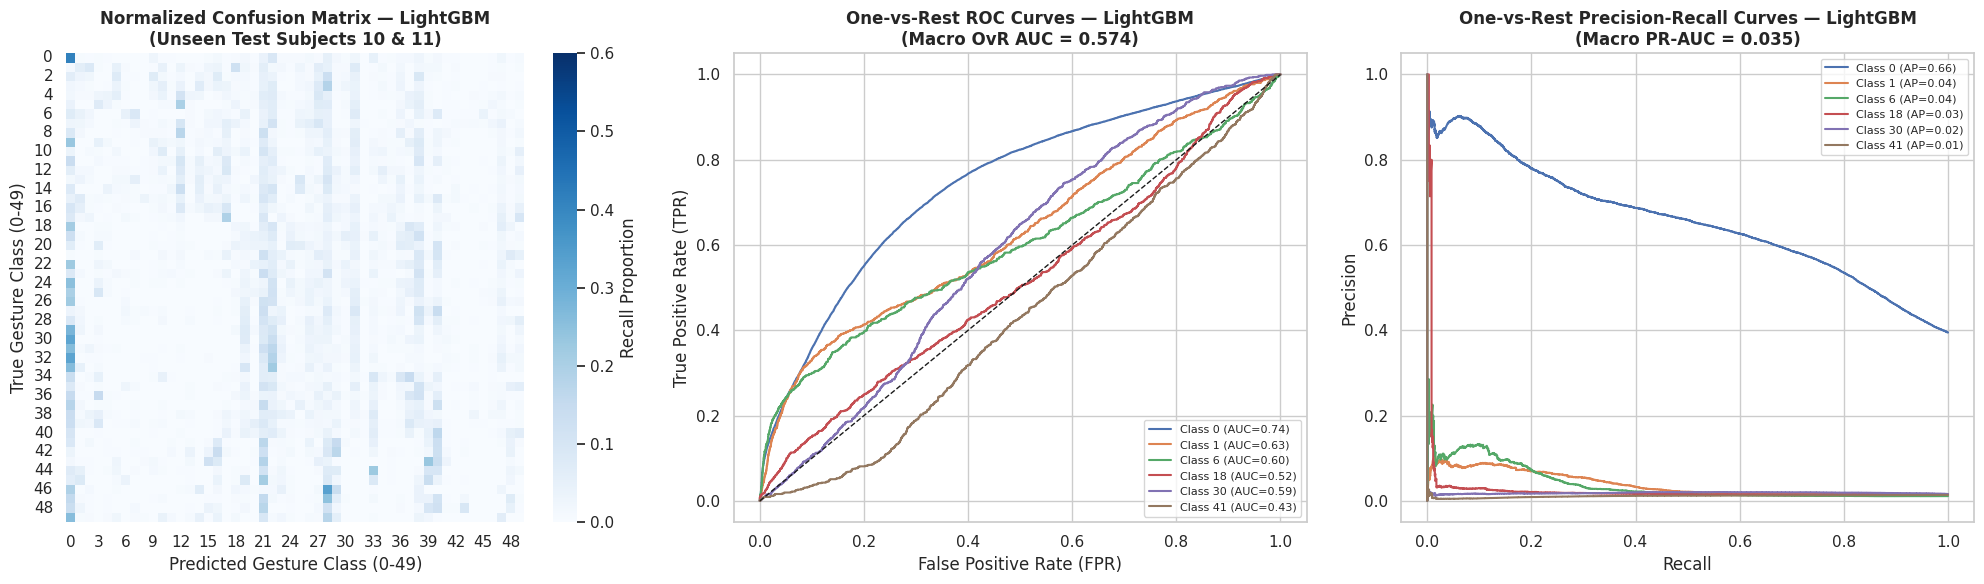

In [ ]:
best_pred = model_predictions[best_model_name]
best_prob = model_probabilities[best_model_name]

fig, axes = plt.subplots(1, 3, figsize=(20, 6))

cm = confusion_matrix(y_test, best_pred, normalize='true')
sns.heatmap(cm, cmap='Blues', vmin=0, vmax=0.6, ax=axes[0], cbar_kws={'label': 'Recall Proportion'})
axes[0].set_title(f'Normalized Confusion Matrix — {best_model_name}\n(Unseen Test Subjects 10 & 11)', fontweight='bold')
axes[0].set_xlabel('Predicted Gesture Class (0-49)')
axes[0].set_ylabel('True Gesture Class (0-49)')

rep_classes = [0, 1, 6, 18, 30, 41]
for c in rep_classes:
    fpr, tpr, _ = roc_curve(y_test_bin[:, c], best_prob[:, c])
    axes[1].plot(fpr, tpr, lw=1.5, label=f'Class {c} (AUC={auc(fpr, tpr):.2f})')
axes[1].plot([0, 1], [0, 1], 'k--', lw=1)
axes[1].set_title(f'One-vs-Rest ROC Curves — {best_model_name}\n(Macro OvR AUC = {best_row["ROC-AUC (OvR)"]:.3f})', fontweight='bold')
axes[1].set_xlabel('False Positive Rate (FPR)')
axes[1].set_ylabel('True Positive Rate (TPR)')
axes[1].legend(fontsize=8, loc='lower right')

for c in rep_classes:
    prec_c, rec_c, _ = precision_recall_curve(y_test_bin[:, c], best_prob[:, c])
    axes[2].plot(rec_c, prec_c, lw=1.5, label=f'Class {c} (AP={average_precision_score(y_test_bin[:, c], best_prob[:, c]):.2f})')
axes[2].set_title(f'One-vs-Rest Precision-Recall Curves — {best_model_name}\n(Macro PR-AUC = {best_row["PR-AUC (OvR)"]:.3f})', fontweight='bold')
axes[2].set_xlabel('Recall')
axes[2].set_ylabel('Precision')
axes[2].legend(fontsize=8, loc='upper right')

plt.tight_layout()
plt.show()